# Bab 10 - Pengenalan Convolutional Neural Networks: Menggunakan Ulang Bobot di Berbagai Tempat

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Jaringan yang kita bangun sejauh ini menggunakan layer **terhubung penuh (fully connected)**: setiap piksel input memiliki bobotnya masing-masing ke setiap node hidden. Bab 10 memperkenalkan **layer konvolusional (convolutional layer)**, salah satu ide paling penting dalam deep learning, berdasarkan pengamatan sederhana: **pola yang sama dapat muncul di mana saja di dalam data** (tepian garis, lengkungan, bentuk mata), sehingga detektor kecil yang sama seharusnya dapat digunakan berulang kali di seluruh bagian gambar.

1. **Menggunakan ulang bobot (reusing weights):** kelompok kecil bobot (sebuah **kernel** atau filter, di sini berukuran 3x3 = 9 bobot) digeser ke seluruh posisi gambar.
2. **Cara layer dihitung:** ekstrak setiap petak 3x3 (**section / patch**) dari gambar; untuk setiap petak, hitung dot product dengan masing-masing kernel. Pada gambar berukuran 28x28 dan kernel 3x3 terdapat 26 x 26 = 676 petak.
3. **Banyak kernel:** menggunakan 16 kernel yang berbeda; masing-masing belajar mendeteksi fitur yang berlainan. Output-nya, berupa 676 x 16 = 10.816 angka per gambar, menjadi input bagi layer fully connected biasa dengan 10 output softmax.
4. **Keuntungan:** jumlah **bobot jauh lebih sedikit** (satu kernel hanya memiliki 9 bobot, bukan 784 per node hidden), **invariansi translasi (translation invariance)** (suatu fitur dapat terdeteksi di mana pun posisinya muncul), dan generalisasi yang lebih baik.
5. **Pelatihan:** backpropagation berjalan sama seperti sebelumnya, perbedaannya adalah gradien untuk setiap kernel **dijumlahkan di seluruh posisi** di mana kernel tersebut diterapkan (karena bobotnya digunakan bersama / shared).

## Teori secara mendalam
* **Konvolusi (cross-correlation):** `out[i, j] = penjumlahan atas a, b dari image[i+a, j+b] * kernel[a, b]`. Kernel bertindak sebagai templat kecil; peta output bernilai besar ketika bagian gambar secara lokal cocok dengan templat tersebut.
* **Pembagian bobot (weight sharing):** karena kernel yang sama diterapkan di setiap posisi, gradiennya adalah **jumlah** dari gradien di setiap posisi tersebut. Dalam bentuk matriks: susun seluruh petak ke dalam matriks `S` berukuran `(posisi, 9)`; maka forward pass adalah `S . K` (K berukuran `9 x 16`) dan gradiennya adalah `S^T . delta`.
* **Jumlah parameter:** layer fully connected dengan 10.816 unit hidden dari 784 piksel akan membutuhkan 784 x 10.816 = 8,5 juta bobot; sedangkan layer konvolusional hanya memiliki 9 x 16 = **144** bobot untuk ekstraksi fiturnya.
* **Stride dan padding:** di sini stride bernilai 1 dan tanpa padding, sehingga gambar 28x28 menyusut menjadi 26x26.
* **Mengapa efektif untuk gambar:** piksel yang berdekatan saling berkorelasi, dan fitur-fitur gambar bersifat lokal serta berulang, yang dimodelkan secara langsung oleh operasi konvolusi.
* Layer setelah konvolusi (tanh) dan layer terakhir (softmax dengan dropout) bekerja persis seperti pada Bab 9.


In [1]:
import gzip
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('..') / 'data' / 'mnist'

def load_images(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

def load_labels(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=8)

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

# buku ini melatih pada 1.000 gambar pertama dan menguji pada seluruh 10.000 gambar uji
x_train = load_images('train-images-idx3-ubyte.gz')[:1000] / 255.0
y_train_raw = load_labels('train-labels-idx1-ubyte.gz')[:1000]
y_train = one_hot(y_train_raw)
x_test = load_images('t10k-images-idx3-ubyte.gz') / 255.0
y_test_raw = load_labels('t10k-labels-idx1-ubyte.gz')
y_test = one_hot(y_test_raw)
print('train:', x_train.shape, y_train.shape, ' test:', x_test.shape, y_test.shape)

train: (1000, 784) (1000, 10)  test: (10000, 784) (10000, 10)


## 1. Mengekstrak setiap bagian 3x3 dari batch gambar


In [2]:
KS = 3                      # ukuran kernel
N_KERNELS = 16
OUT = 28 - KS + 1           # 26 posisi per sisi

def get_sections(images):
    # gambar: (batch, 784) -> matriks (batch * 26 * 26, 9): satu baris per petak 3x3
    imgs = images.reshape(-1, 28, 28)
    windows = np.lib.stride_tricks.sliding_window_view(imgs, (KS, KS), axis=(1, 2))   # (B, 26, 26, 3, 3)
    return windows.reshape(-1, KS * KS)

demo = get_sections(x_train[:1])
print('sections for one image:', demo.shape, ' (676 patches of 9 pixels)')

# bandingkan dengan perulangan eksplisit untuk satu petak tunggal
img = x_train[0].reshape(28, 28)
assert np.allclose(demo[5 * OUT + 7], img[5:8, 7:10].ravel())
print('patch at row 5, col 7 matches the explicit slice: OK')

sections for one image: (676, 9)  (676 patches of 9 pixels)
patch at row 5, col 7 matches the explicit slice: OK


## 2. Jaringan konvolusional (CNN)
`gambar (28x28)` -> **16 kernel 3x3** -> `tanh` -> flatten (10.816) -> dropout -> **softmax atas 10 digit**.


In [3]:
def tanh(x): return np.tanh(x)
def tanh2deriv(out): return 1 - out ** 2
def softmax(x):
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def forward(images, kernels, w12, dropout_mask=None):
    sections = get_sections(images)                               # (B*676, 9)
    conv = sections.dot(kernels)                                  # (B*676, 16)
    l1 = tanh(conv.reshape(len(images), -1))                      # (B, 10816)
    l1d = l1 if dropout_mask is None else l1 * dropout_mask * 2
    return sections, l1, l1d, softmax(l1d.dot(w12))

def accuracy_chunked(kernels, w12, x, y_raw, chunk=500):
    hits = 0
    for s in range(0, len(x), chunk):
        probs = forward(x[s:s + chunk], kernels, w12)[3]
        hits += np.sum(probs.argmax(1) == y_raw[s:s + chunk])
    return hits / len(x)

def train_cnn(alpha=0.05, batch_size=128, iterations=100, seed=1, eval_every=20):
    np.random.seed(seed)
    kernels = 0.02 * np.random.random((KS * KS, N_KERNELS)) - 0.01
    w12 = 0.2 * np.random.random((OUT * OUT * N_KERNELS, 10)) - 0.1
    log = []
    n_batches = len(x_train) // batch_size
    for it in range(iterations):
        correct = 0
        for b in range(n_batches):
            s, e = b * batch_size, (b + 1) * batch_size
            mask = np.random.randint(2, size=(batch_size, OUT * OUT * N_KERNELS))
            sections, l1, l1d, l2 = forward(x_train[s:e], kernels, w12, mask)
            correct += np.sum(l2.argmax(1) == y_train_raw[s:e])

            d2 = (l2 - y_train[s:e]) / batch_size
            d1 = d2.dot(w12.T) * mask * 2 * tanh2deriv(l1)       # mundur melewati dropout dan tanh
            w12 -= alpha * l1d.T.dot(d2)
            kernels -= alpha * sections.T.dot(d1.reshape(-1, N_KERNELS))   # gradien DIJUMLAHKAN di seluruh posisi
        if (it + 1) % eval_every == 0 or it == iterations - 1:
            te = accuracy_chunked(kernels, w12, x_test, y_test_raw)
            log.append((it + 1, correct / (n_batches * batch_size), te))
            print(f'iteration {it + 1:3d}   train acc (with dropout, running) {log[-1][1]:.3f}   test acc {te:.3f}')
    return np.array(log), kernels, w12

Perhatikan bahwa akurasi pelatihan yang dicetak selama proses pelatihan dihitung *dengan dropout yang aktif* serta saat bobot masih terus diperbarui, sehingga nilainya lebih rendah dari akurasi pelatihan yang sebenarnya dan hanya berfungsi sebagai indikator progres.


In [4]:
import time
t0 = time.time()
log10, kernels, w12 = train_cnn(iterations=100, eval_every=20)
print(f'training took {time.time() - t0:.0f}s')

iteration  20   train acc (with dropout, running) 0.827   test acc 0.845


iteration  40   train acc (with dropout, running) 0.898   test acc 0.861


iteration  60   train acc (with dropout, running) 0.917   test acc 0.867


iteration  80   train acc (with dropout, running) 0.922   test acc 0.864


iteration 100   train acc (with dropout, running) 0.933   test acc 0.865
training took 51s


CNN mencapai akurasi sekitar 86-87% pada 10.000 gambar uji setelah dilatih hanya pada 1.000 gambar, yang kurang lebih setara dengan jaringan fully connected pada Bab 8 dan 9 dengan data yang sama (sekitar 86-88%). Jadi pada dataset pelatihan kecil ini, layer konvolusional tidak memberikan lonjakan akurasi yang signifikan; yang diberikannya adalah pengurangan jumlah bobot yang sangat drastis pada layer ekstraksi fitur (lihat perbandingan jumlah parameter di bawah). Akurasi uji berhenti meningkat setelah sekitar 60 iterasi sementara akurasi latih terus naik, yang merupakan indikasi overfitting seperti yang dibahas pada Bab 8.


## 3. Apa yang dipelajari oleh kernel?


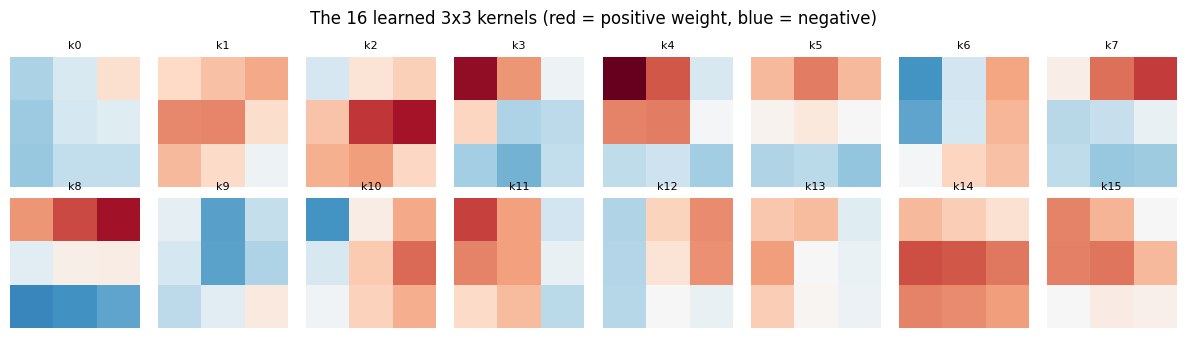

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(kernels[:, k].reshape(3, 3), cmap='RdBu', vmin=-abs(kernels).max(), vmax=abs(kernels).max())
    ax.axis('off'); ax.set_title(f'k{k}', fontsize=8)
plt.suptitle('The 16 learned 3x3 kernels (red = positive weight, blue = negative)')
plt.tight_layout(); plt.show()

Setiap kernel 3x3 merupakan detektor pola kecil: sebuah kernel merespons dengan kuat di mana pun petak 3x3 pada gambar menyerupai polanya (misalnya goresan garis ke arah tertentu). Dengan hanya 9 bobot per kernel, pola-polanya sangat sederhana dan tidak selalu tampak seperti tepian garis yang rapi. Karena 9 bobot yang sama diterapkan pada seluruh 676 posisi, jaringan dapat mendeteksi fitur tersebut di mana pun letaknya pada gambar.

### Peta fitur (feature maps) untuk satu gambar


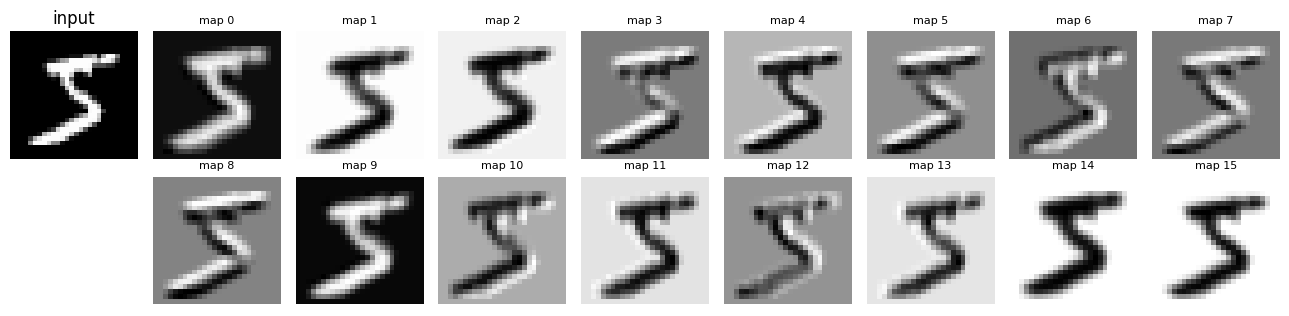

predicted digit: 5   true digit: 5


In [6]:
sec, l1, _, probs = forward(x_train[:1], kernels, w12)
maps = l1.reshape(OUT, OUT, N_KERNELS)
fig, axes = plt.subplots(2, 9, figsize=(13, 3.2))
axes[0, 0].imshow(x_train[0].reshape(28, 28), cmap='gray'); axes[0, 0].set_title('input'); axes[0, 0].axis('off')
for ax in axes[1, :1]: ax.axis('off')
for k in range(16):
    ax = axes.ravel()[1 + k] if k < 8 else axes.ravel()[10 + k - 8]
    ax.imshow(maps[:, :, k], cmap='gray'); ax.axis('off'); ax.set_title(f'map {k}', fontsize=8)
plt.tight_layout(); plt.show()
print('predicted digit:', probs.argmax(), '  true digit:', y_train_raw[0])

## 4. Jumlah parameter: konvolusional vs fully connected


In [7]:
conv_params = KS * KS * N_KERNELS
fc_equivalent = 784 * (OUT * OUT * N_KERNELS)
print(f'convolution layer weights:                       {conv_params:,}')
print(f'a fully connected layer with the same output size: {fc_equivalent:,}')
print(f'ratio: {fc_equivalent / conv_params:,.0f}x fewer weights with weight sharing')

convolution layer weights:                       144
a fully connected layer with the same output size: 8,479,744
ratio: 58,887x fewer weights with weight sharing


## Poin-poin kunci
* Layer konvolusional menerapkan kernel kecil yang sama di setiap posisi input dengan membagi bobotnya (weight sharing).
* Forward pass: ekstrak seluruh petak, kalikan dengan matriks kernel; backward pass: gradien kernel menjumlahkan kontribusi dari setiap posisi.
* Pembagian bobot memangkas jumlah parameter secara drastis dan membuat pendeteksian fitur tidak bergantung pada letak kemunculannya (invariansi translasi).
* Sisa arsitektur jaringan lainnya (tanh, dropout, softmax, mini-batch) tetap bekerja persis seperti pada Bab 8 dan 9.
